## 0: import data

In [128]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import ast
from scipy.stats import trim_mean

netflix = pd.read_csv("../content_libraries/netflix_2022/netflix_titles_2022.csv")
amazon = pd.read_csv("../content_libraries/amazon_2022/amazon_titles_2022.csv")

FileNotFoundError: [Errno 2] No such file or directory: 'content_libraries/netflix_2022/netflix_titles_2022.csv'

## 1.0: Info on the netflix dataset

In [129]:
netflix.head()
netflix.info()
netflix.describe()


<class 'pandas.DataFrame'>
RangeIndex: 5850 entries, 0 to 5849
Data columns (total 15 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   id                    5850 non-null   str    
 1   title                 5849 non-null   str    
 2   type                  5850 non-null   str    
 3   description           5832 non-null   str    
 4   release_year          5850 non-null   int64  
 5   age_certification     3231 non-null   str    
 6   runtime               5850 non-null   int64  
 7   genres                5850 non-null   str    
 8   production_countries  5850 non-null   str    
 9   seasons               2106 non-null   float64
 10  imdb_id               5447 non-null   str    
 11  imdb_score            5368 non-null   float64
 12  imdb_votes            5352 non-null   float64
 13  tmdb_popularity       5759 non-null   float64
 14  tmdb_score            5539 non-null   float64
dtypes: float64(5), int64(2), str(8)


,release_year,runtime,seasons,imdb_score,imdb_votes,tmdb_popularity,tmdb_score
count,5850.000000,5850.000000,2106.000000,5368.000000,5.352000e+03,5759.000000,5539.000000
mean,2016.417094,76.888889,2.162868,6.510861,2.343938e+04,22.637925,6.829175
std,6.937726,39.002509,2.689041,1.163826,9.582047e+04,81.680263,1.170391
min,1945.000000,0.000000,1.000000,1.500000,5.000000e+00,0.009442,0.500000
25%,2016.000000,44.000000,1.000000,5.800000,5.167500e+02,2.728500,6.100000
50%,2018.000000,83.000000,1.000000,6.600000,2.233500e+03,6.821000,6.900000
75%,2020.000000,104.000000,2.000000,7.300000,9.494000e+03,16.590000,7.537500
max,2022.000000,240.000000,42.000000,9.600000,2.294231e+06,2274.044000,10.000000


In [130]:
netflix.head()

,id,title,type,description,release_year,age_certification,runtime,genres,production_countries,seasons,imdb_id,imdb_score,imdb_votes,tmdb_popularity,tmdb_score
0,ts300399,Five Came Back: The Reference Films,SHOW,This collection includes 12 World War II-era p...,1945,TV-MA,51,['documentation'],['US'],1.0,NaN,NaN,NaN,0.600,NaN
1,tm84618,Taxi Driver,MOVIE,A mentally unstable Vietnam War veteran works ...,1976,R,114,"['drama', 'crime']",['US'],NaN,tt0075314,8.2,808582.0,40.965,8.179
2,tm154986,Deliverance,MOVIE,Intent on seeing the Cahulawassee River before...,1972,R,109,"['drama', 'action', 'thriller', 'european']",['US'],NaN,tt0068473,7.7,107673.0,10.010,7.300
3,tm127384,Monty Python and the Holy Grail,MOVIE,"King Arthur, accompanied by his squire, recrui...",1975,PG,91,"['fantasy', 'action', 'comedy']",['GB'],NaN,tt0071853,8.2,534486.0,15.461,7.811
4,tm120801,The Dirty Dozen,MOVIE,12 American military prisoners in World War II...,1967,NaN,150,"['war', 'action']","['GB', 'US']",NaN,tt0061578,7.7,72662.0,20.398,7.600


(5850, 15)
Index(['id', 'title', 'type', 'description', 'release_year',
       'age_certification', 'runtime', 'genres', 'production_countries',
       'seasons', 'imdb_id', 'imdb_score', 'imdb_votes', 'tmdb_popularity',
       'tmdb_score'],
      dtype='str')
id                         0
title                      1
type                       0
description               18
release_year               0
age_certification       2619
runtime                    0
genres                     0
production_countries       0
seasons                 3744
imdb_id                  403
imdb_score               482
imdb_votes               498
tmdb_popularity           91
tmdb_score               311
dtype: int64


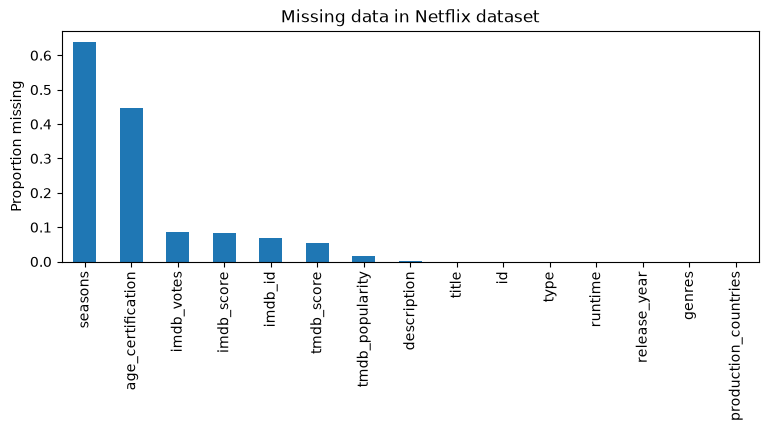

In [ ]:
# how many null values?
print(netflix.shape)
print(netflix.columns)
print(netflix.isna().sum())
# dupes check titles

missing_netflix = netflix.isnull().mean().sort_values(ascending=False)

missing_netflix.plot(kind="bar", figsize=(9,3))
plt.ylabel("Proportion missing")
plt.title("Missing data in Netflix dataset")
plt.show()

In [ ]:
# need to remove nan values for

In [132]:
# drop dups values for netflix
netflix_dup = netflix.drop_duplicates().any()
print(netflix_dup)

id                      True
title                   True
type                    True
description             True
release_year            True
age_certification       True
runtime                 True
genres                  True
production_countries    True
seasons                 True
imdb_id                 True
imdb_score              True
imdb_votes              True
tmdb_popularity         True
tmdb_score              True
dtype: bool


In [133]:
# need to drop for id, imdb_id
netflix = netflix.drop_duplicates(subset=['imdb_id', 'id'], keep = False)
print(netflix.duplicated(subset=['imdb_id', 'id']).sum())

0


##  1.1: Info on the amazon dataset

In [134]:
amazon.head()
amazon.info()
amazon.describe()

<class 'pandas.DataFrame'>
RangeIndex: 9871 entries, 0 to 9870
Data columns (total 15 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   id                    9871 non-null   str    
 1   title                 9871 non-null   str    
 2   type                  9871 non-null   str    
 3   description           9752 non-null   str    
 4   release_year          9871 non-null   int64  
 5   age_certification     3384 non-null   str    
 6   runtime               9871 non-null   int64  
 7   genres                9871 non-null   str    
 8   production_countries  9871 non-null   str    
 9   seasons               1357 non-null   float64
 10  imdb_id               9204 non-null   str    
 11  imdb_score            8850 non-null   float64
 12  imdb_votes            8840 non-null   float64
 13  tmdb_popularity       9324 non-null   float64
 14  tmdb_score            7789 non-null   float64
dtypes: float64(5), int64(2), str(8)


,release_year,runtime,seasons,imdb_score,imdb_votes,tmdb_popularity,tmdb_score
count,9871.000000,9871.000000,1357.000000,8850.000000,8.840000e+03,9324.000000,7789.000000
mean,2001.327221,85.973052,2.791452,5.976395,8.533614e+03,6.910204,5.984247
std,25.810071,33.512466,4.148958,1.343842,4.592015e+04,30.004098,1.517986
min,1912.000000,1.000000,1.000000,1.100000,5.000000e+00,0.000011,0.800000
25%,1995.500000,65.000000,1.000000,5.100000,1.170000e+02,1.232000,5.100000
50%,2014.000000,89.000000,1.000000,6.100000,4.625000e+02,2.536000,6.000000
75%,2018.000000,102.000000,3.000000,6.900000,2.236250e+03,5.634000,6.900000
max,2022.000000,549.000000,51.000000,9.900000,1.133692e+06,1437.906000,10.000000


(9865, 16)
Index(['id', 'title', 'type', 'description', 'release_year',
       'age_certification', 'runtime', 'genres', 'production_countries',
       'seasons', 'imdb_id', 'imdb_score', 'imdb_votes', 'tmdb_popularity',
       'tmdb_score', 'service'],
      dtype='str')
id                         0
title                      0
type                       0
description              119
release_year               0
age_certification       6481
runtime                    0
genres                     0
production_countries       0
seasons                 8508
imdb_id                  667
imdb_score              1021
imdb_votes              1031
tmdb_popularity          547
tmdb_score              2078
service                    0
dtype: int64


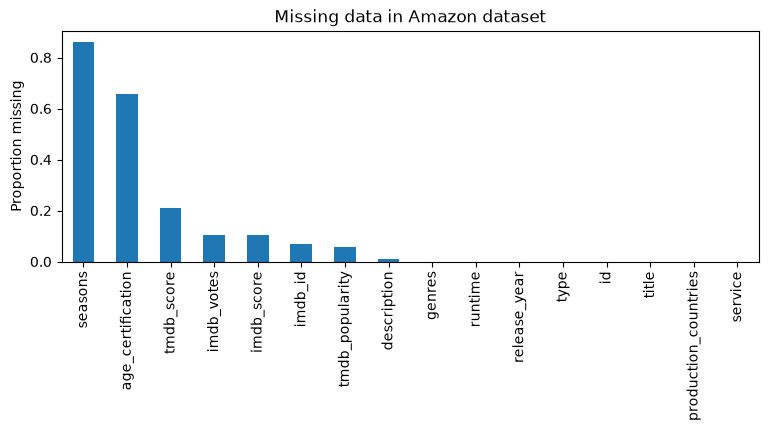

In [166]:
# how many null values?
print(amazon.shape)
print(amazon.columns)
print(amazon.isna().sum())

missing_amazon = amazon.isnull().mean().sort_values(ascending=False)

missing_amazon.plot(kind="bar", figsize=(9,3))
plt.ylabel("Proportion missing")
plt.title("Missing data in Amazon dataset")
plt.show()

In [136]:
# drop dups values for netflix
amazon_dup = amazon.drop_duplicates().any()
print(amazon_dup)

id                      True
title                   True
type                    True
description             True
release_year            True
age_certification       True
runtime                 True
genres                  True
production_countries    True
seasons                 True
imdb_id                 True
imdb_score              True
imdb_votes              True
tmdb_popularity         True
tmdb_score              True
dtype: bool


In [137]:
# need to drop for id, imdb_id
amazon = amazon.drop_duplicates(subset=['imdb_id', 'id'], keep = False)
print(amazon.duplicated(subset=['imdb_id', 'id']).sum())

0


## 2.0: Combine the two datasets

In [138]:
netflix["service"] = "Netflix"
amazon["service"] = "Amazon Prime"
catalog = pd.concat([netflix, amazon], ignore_index=True)


# change to numeric values to be certain they gets read correctly
catalog["release_year"] = pd.to_numeric(
    catalog["release_year"], errors="coerce"
)

catalog["imdb_score"] = pd.to_numeric(
    catalog["imdb_score"], errors="coerce"
)

catalog["imdb_votes"] = pd.to_numeric(
    catalog["imdb_votes"], errors="coerce"
)

catalog["content_age"] = 2022 - catalog["release_year"]


## 3.0: Distribution of movies and TV shows for both services (Number of titles available)

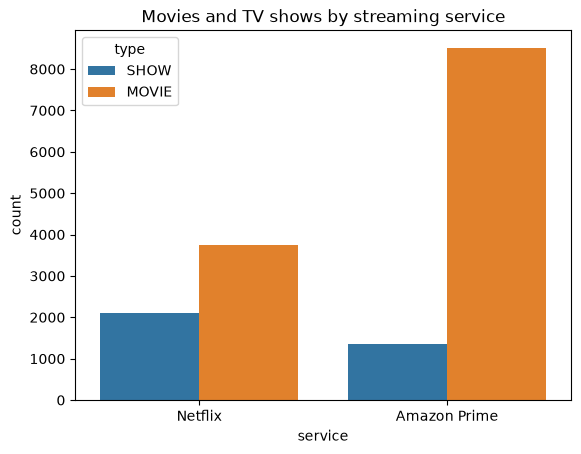

type          MOVIE  SHOW
service                  
Amazon Prime   8508  1357
Netflix        3744  2106


In [139]:
sns.countplot(data=catalog, x="service", hue="type")
plt.title("Movies and TV shows by streaming service")
plt.show()

print(catalog.groupby(["service", "type"]).size().unstack(fill_value=0))

## 3.1 Percentage of difference in moive and series for each service

In [140]:
pd.crosstab(
    catalog["service"],
    catalog["type"],
    normalize="index"
) * 100

type,MOVIE,SHOW
service,,
Amazon Prime,86.244298,13.755702
Netflix,64.000000,36.000000


note: Netflix's 2022 catalog consisted of 64% movies and 36% TV shows, while Amazon's consisted of 86.25% and 13.75%

## 4:0 Age of the content avaliable (release year distribution)

In [141]:

# Calculate content age
catalog["content_age"] = 2022 - catalog["release_year"]

# Compare robust and non-robust measures
age_summary = catalog.groupby("service")["content_age"].agg(
    mean="mean",
    median="median",
    count="count"
)

# Add 10% trimmed mean
trimmed_means = catalog.groupby("service")["content_age"].apply(
    lambda x: trim_mean(x.dropna(), proportiontocut=0.10)
)

age_summary["trimmed_mean"] = trimmed_means

print(age_summary.round(2))


               mean  median  count  trimmed_mean
service                                         
Amazon Prime  20.64     8.0   9865         15.32
Netflix        5.58     4.0   5850          4.16


Note: Its median content age is 8 years, compared with 4 years for Netflix. This means that half of Amazon Primes catelog was released 8 years before 2022, compared to Netlfix's 4 years before 2022. The median-mean gap of Amazon Prime, with a median of 8.0 years and a mean of 20.67 years suggests a right-skewed distribution, where a relatively small number of very old titles pull the mean upward. Netflix is less effected by extreme ages, with a trimmed mean of 4.16 years compared with a mean of 5.58 years. 

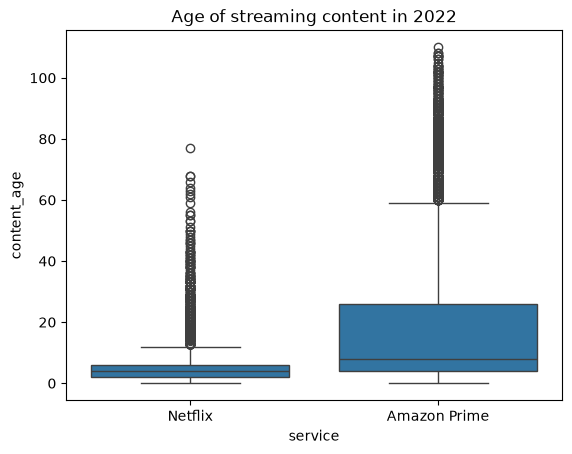

In [142]:
catalog["content_age"] = 2022 - catalog["release_year"]

sns.boxplot(data=catalog, x="service", y="content_age")
plt.title("Age of streaming content in 2022")
plt.show()


## Zoom in of the boxplot (Content age by streaming in 2022)

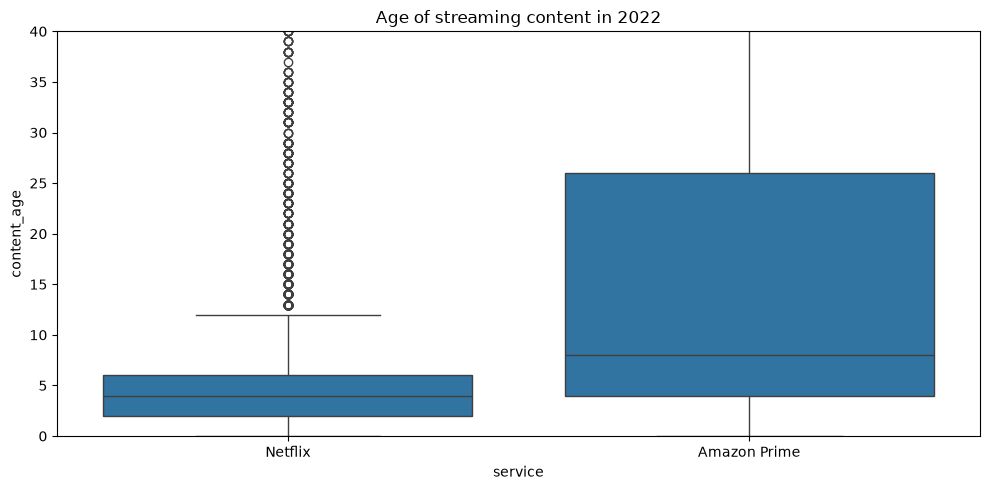

service
Amazon Prime    2001.363913
Netflix         2016.417094
Name: release_year, dtype: float64

In [143]:
plt.figure(figsize=(10, 5))

sns.boxplot(
    data=catalog,
    x="service",
    y="content_age"
)

plt.ylim(0, 40)
plt.title("Age of streaming content in 2022")
plt.tight_layout()
plt.show()

# average release year
catalog.groupby("service")["release_year"].mean()

Note: From the boxplot it is shown that Amazon prime has a greater distribution spread of release years. While, Netflix's core catalog shows low variability, heavily concentrating on newer releases. 
This then make sense that the mean for Amazon prime is 2001 compared to Netflix at 2016.
Futhermore, both platforms carry a very long "tail" of classic or vintage movies and television shows. Amazon Prime simply dominates in the ultra-vintage category, hosting titles that are over a century old.


## 4.1 New vs. old content 
(define new bestween 2018 - 2022)

content_category  New content (2018–2022)  Older content (before 2018)
service                                                               
Amazon Prime                        31.78                        68.22
Netflix                             61.21                        38.79


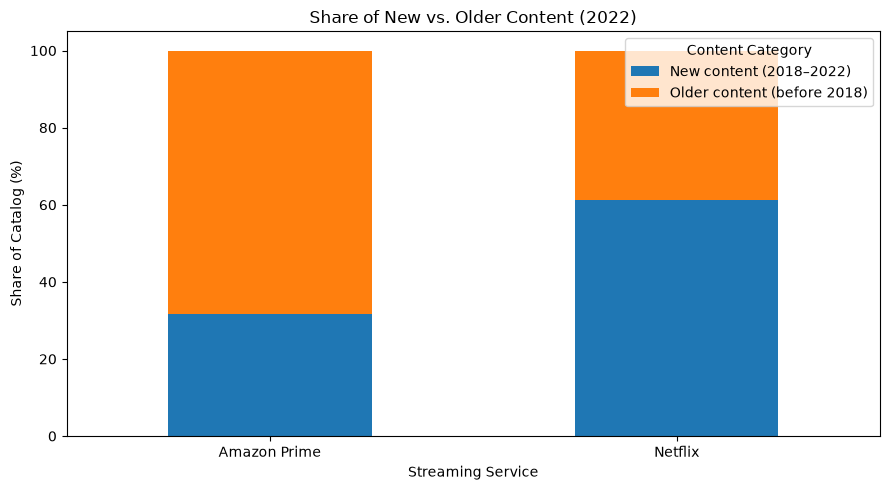

In [144]:
catalog["release_year"] = pd.to_numeric(
    catalog["release_year"], errors="coerce"
)

catalog["content_category"] = np.select(
    [
        catalog["release_year"].between(2018, 2022),
        catalog["release_year"] < 2018
    ],
    [
        "New content (2018–2022)",
        "Older content (before 2018)"
    ],
    default=None
)
content_share = pd.crosstab(
    catalog["service"],
    catalog["content_category"],
    normalize="index"
) * 100

print(content_share.round(2))

content_share.plot(
    kind="bar",
    stacked=True,
    figsize=(9, 5)
)

plt.title("Share of New vs. Older Content (2022)")
plt.xlabel("Streaming Service")
plt.ylabel("Share of Catalog (%)")
plt.legend(title="Content Category")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 5.1 Define vote-count ranges

In [145]:
#Inspect the distribution of IMDb vote counts
votes = catalog["imdb_votes"].dropna()

print("IMDb vote-count summary:")
print(votes.describe(
    percentiles=[.10, .25, .50, .75, .90, .95, .99]
))

print("\nSkewness:", round(votes.skew(), 2))
print("Zero votes:", (votes == 0).sum())
print("Negative votes:", (votes < 0).sum())
print("Missing votes:", catalog["imdb_votes"].isna().sum())

IMDb vote-count summary:
count    1.418600e+04
mean     1.416074e+04
std      6.949563e+04
min      5.000000e+00
10%      5.100000e+01
25%      1.770000e+02
50%      8.275000e+02
75%      4.315750e+03
90%      2.143250e+04
95%      5.575950e+04
99%      2.751944e+05
max      2.294231e+06
Name: imdb_votes, dtype: float64

Skewness: 13.77
Zero votes: 0
Negative votes: 0
Missing votes: 1529


In [146]:
# 2. Define bins based on the observed distribution

# Cutoffs are informed by the observed quantiles.
# The lower bound of 4 ensures that votes below 5
# are not included in the first category.

bins = [
    5, 50, 200, 1000, 5000,
    20000, 60000, np.inf
]

labels = [
    "5–50",
    "51–200",
    "201–1,000",
    "1,001–5,000",
    "5,001–20,000",
    "20,001–60,000",
    "60,001+"
]

# Categorise IMDb vote counts
catalog["vote_status"] = pd.cut(
    catalog["imdb_votes"],
    bins=bins,
    labels=labels,
    include_lowest=True
)


# Add categories for low and missing vote counts
catalog["vote_status"] = (
    catalog["vote_status"].cat.add_categories(
        ["Below 5", "Missing"]
    )
)

# Assign titles with fewer than 5 votes to a separate category
catalog.loc[
    catalog["imdb_votes"] < 5,
    "vote_status"
] = "Below 5"

# Keep missing vote counts separate
catalog.loc[
    catalog["imdb_votes"].isna(),
    "vote_status"
] = "Missing"


In [147]:
# Check overall group sizes
group_summary = pd.DataFrame({
    "count": catalog["vote_status"].value_counts(sort=False),
    "percentage": (
        catalog["vote_status"].value_counts(sort=False, normalize=True)
        * 100
    )
})

print("\nOverall vote-count categories:")
print(group_summary.round(2))



Overall vote-count categories:
               count  percentage
vote_status                     
5–50            1418        9.02
51–200          2388       15.20
201–1,000       3712       23.62
1,001–5,000     3379       21.50
5,001–20,000    1799       11.45
20,001–60,000    818        5.21
60,001+          672        4.28
Below 5            0        0.00
Missing         1529        9.73


In [148]:
# Count titles in each vote category by service
vote_counts = pd.crosstab(
    catalog["service"],
    catalog["vote_status"]
)

print("Vote-count categories (number of titles):")
print(vote_counts)


Vote-count categories (number of titles):
vote_status   5–50  51–200  201–1,000  1,001–5,000  5,001–20,000  \
service                                                            
Amazon Prime  1158    1914       2535         1796           847   
Netflix        260     474       1177         1583           952   

vote_status   20,001–60,000  60,001+  Missing  
service                                        
Amazon Prime            329      255     1031  
Netflix                 489      417      498  


In [149]:
# Compare percentages within each service
vote_percentages = pd.crosstab(
    catalog["service"],
    catalog["vote_status"],
    normalize="index",
    dropna=False
) * 100

print("\nVote-count categories by service (percentages):")
print(vote_percentages.round(2))



Vote-count categories by service (percentages):
vote_status    5–50  51–200  201–1,000  1,001–5,000  5,001–20,000  \
service                                                             
Amazon Prime  11.74    19.4      25.70        18.21          8.59   
Netflix        4.44     8.1      20.12        27.06         16.27   

vote_status   20,001–60,000  60,001+  Below 5  Missing  
service                                                 
Amazon Prime           3.34     2.58      0.0    10.45  
Netflix                8.36     7.13      0.0     8.51  


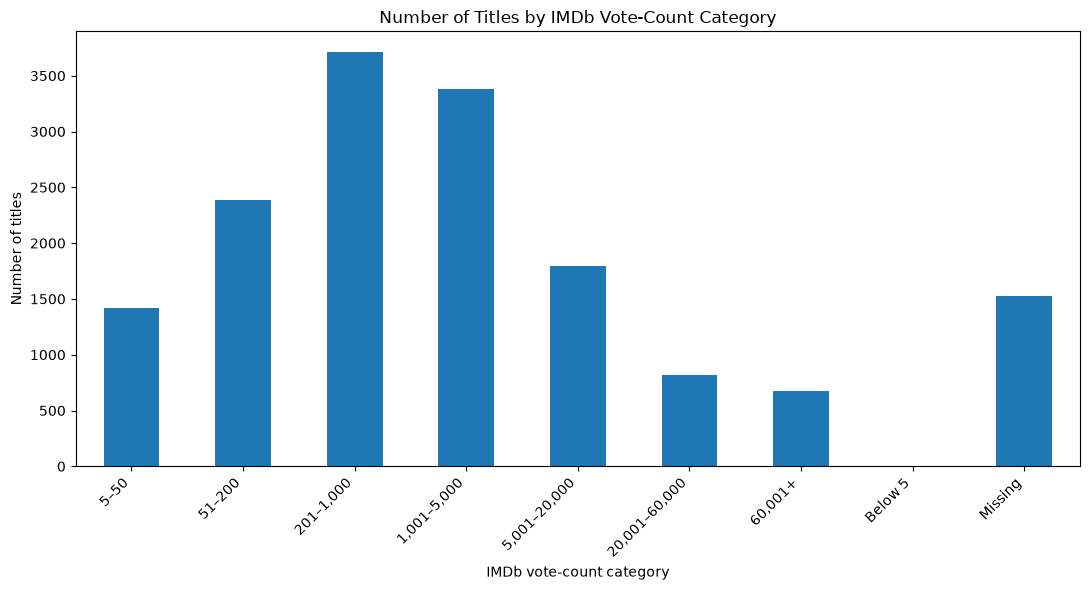

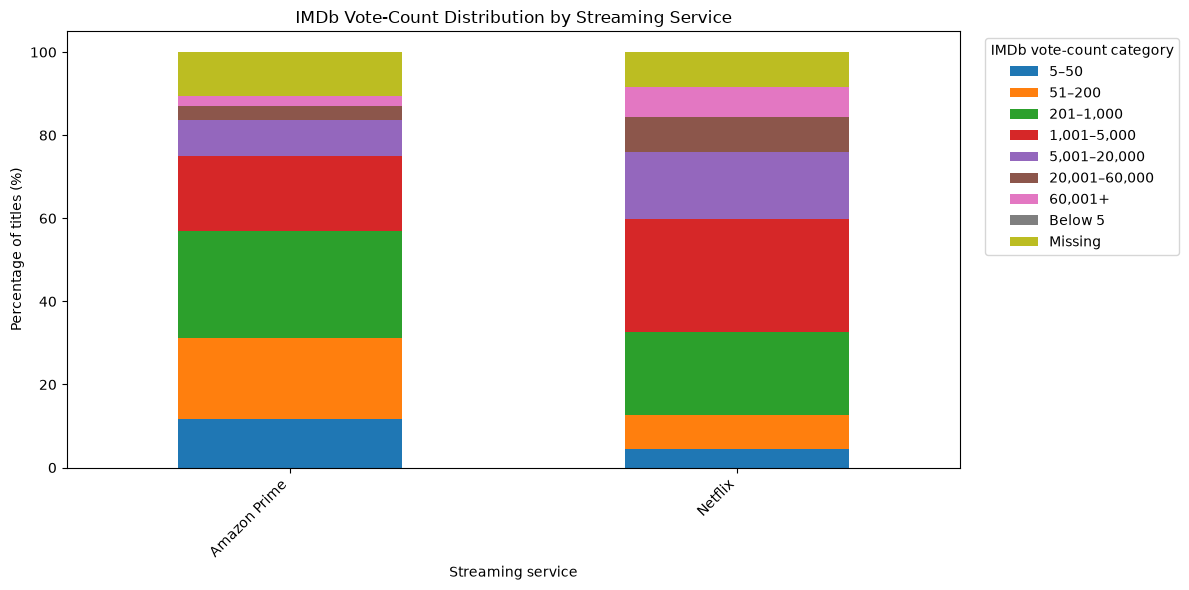

In [150]:
# Visualise group sizes overall
group_summary["count"].plot(
    kind="bar",
    figsize=(11, 6)
)

plt.title("Number of Titles by IMDb Vote-Count Category")
plt.xlabel("IMDb vote-count category")
plt.ylabel("Number of titles")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


#  Visualise percentages by streaming service
vote_percentages.plot(
    kind="bar",
    stacked=True,
    figsize=(12, 6)
)

plt.title("IMDb Vote-Count Distribution by Streaming Service")
plt.xlabel("Streaming service")
plt.ylabel("Percentage of titles (%)")
plt.legend(
    title="IMDb vote-count category",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


## 5.2 Rating stability at different vote levels

In [151]:
# Keep titles with at least 5 IMDb votes and non-missing vote counts
votes_data = catalog[
    catalog["imdb_votes"].notna() &
    (catalog["imdb_votes"] >= 5)
].copy()

# Define vote-count ranges based on the observed distribution
bins = [
    5, 51, 201, 1001, 5001,
    20001, 60001, np.inf
]

labels = [
    "5–50",
    "51–200",
    "201–1,000",
    "1,001–5,000",
    "5,001–20,000",
    "20,001–60,000",
    "60,001+"
]

# Categorise vote counts
votes_data["vote_group"] = pd.cut(
    votes_data["imdb_votes"],
    bins=bins,
    labels=labels,
    right=False
)

# Summarise IMDb ratings within each service and vote group
rating_summary = votes_data.groupby(
    ["service", "vote_group"], observed=False
)["imdb_score"].agg(
    count="count",
    mean="mean",
    median="median",
    std="std"
)

print("IMDb rating summary by service and vote group:")
print(rating_summary.round(2))

IMDb rating summary by service and vote group:
                            count  mean  median   std
service      vote_group                              
Amazon Prime 5–50            1158  6.22     6.4  1.48
             51–200          1914  5.71     5.8  1.33
             201–1,000       2535  5.63     5.7  1.29
             1,001–5,000     1796  6.04     6.2  1.23
             5,001–20,000     847  6.44     6.5  1.14
             20,001–60,000    329  6.80     6.9  1.15
             60,001+          255  7.28     7.3  0.90
Netflix      5–50             260  6.40     6.5  1.36
             51–200           474  6.07     6.2  1.21
             201–1,000       1177  6.21     6.4  1.14
             1,001–5,000     1583  6.52     6.6  1.09
             5,001–20,000     952  6.67     6.8  1.15
             20,001–60,000    489  6.75     6.9  1.06
             60,001+          417  7.25     7.3  0.99


## 6.0 Content quality based on imdb rating

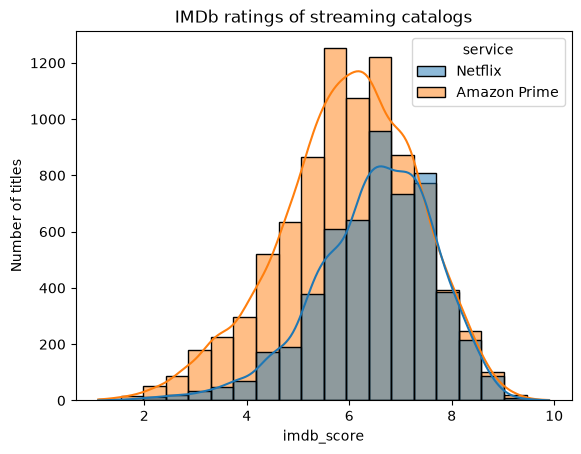

,mean,median,std,count
service,,,,
Amazon Prime,5.976673,6.1,1.344214,8844
Netflix,6.510861,6.6,1.163826,5368


In [171]:
sns.histplot(
    data=catalog,
    x="imdb_score",
    hue="service",
    kde=True,
    bins=20
)

plt.title("IMDb ratings of streaming catalogs")
plt.ylabel('Number of titles')
plt.show()


catalog.groupby("service")["imdb_score"].agg(
    ["mean", "median", "std", "count"]
)

# not sufficent: if catelog increases but the number of high-rated titels
# stay the same, it should not be punished with a lower average rating

## 6.1  Create upper bound for high-quality content measure

In [175]:
# define what the threshold is for included imdb based on the bins in section 5.0
# Define what high_quality is in this case
catalog["high_quality"] = (
    (catalog["imdb_score"] >= 7) 
    #&
    #(catalog["imdb_votes"] >= 60000)
)

high_quality_stats = (
    catalog.groupby("service")
    .agg(
        total_titles=("imdb_id", "count"),
        high_quality_titles=("high_quality", "sum"),
        high_quality_share=("high_quality", "mean")
    )
)

high_quality_stats["high_quality_share"] *= 100

high_quality_stats.round(2)

# - high_quality_share:
#   What proportion of the catalog is highly rated? 
# - high_quality_titels:
# How many highly rated titles can consumers access?


# explores the idea of The average rating might barely change,
# but the amount of highly rated content available per title has decreased?


,total_titles,high_quality_titles,high_quality_share
service,,,
Amazon Prime,9198,2202,22.32
Netflix,5447,2070,35.38


In [154]:
# answers: What is the overall quality of the catalog?
quality_comparison = (
    catalog.groupby("service")
    .agg(
        number_of_titles=("imdb_id", "count"),
        average_imdb=("imdb_score", "mean"),
        median_imdb_votes=("imdb_votes", "median"),
        high_quality_titles=("high_quality", "sum"),
        high_quality_share=("high_quality", "mean")
    )
)

quality_comparison["high_quality_share"] *= 100

quality_comparison.round(2)

,number_of_titles,average_imdb,median_imdb_votes,high_quality_titles,high_quality_share
service,,,,,
Amazon Prime,9198,5.98,464.0,2202,22.32
Netflix,5447,6.51,2233.5,2070,35.38


## 7.0 Genre distribution across services

In [155]:

catalog["genres"] = catalog["genres"].fillna("[]")
catalog["genres"] = catalog["genres"].apply(ast.literal_eval)

genres = catalog.explode("genres")

genres["genres"] = genres["genres"].str.strip()

# number of movies and tv shows in each genre
genre_counts = genres.groupby("genres").size().sort_values(ascending=False)

print(genre_counts)


genres
drama            7728
comedy           5312
thriller         3347
action           2977
romance          2721
crime            2185
documentation    2048
horror           1443
family           1433
scifi            1294
fantasy          1184
animation        1180
european         1155
music             700
history           650
western           529
war               487
sport             398
reality           372
dtype: int64


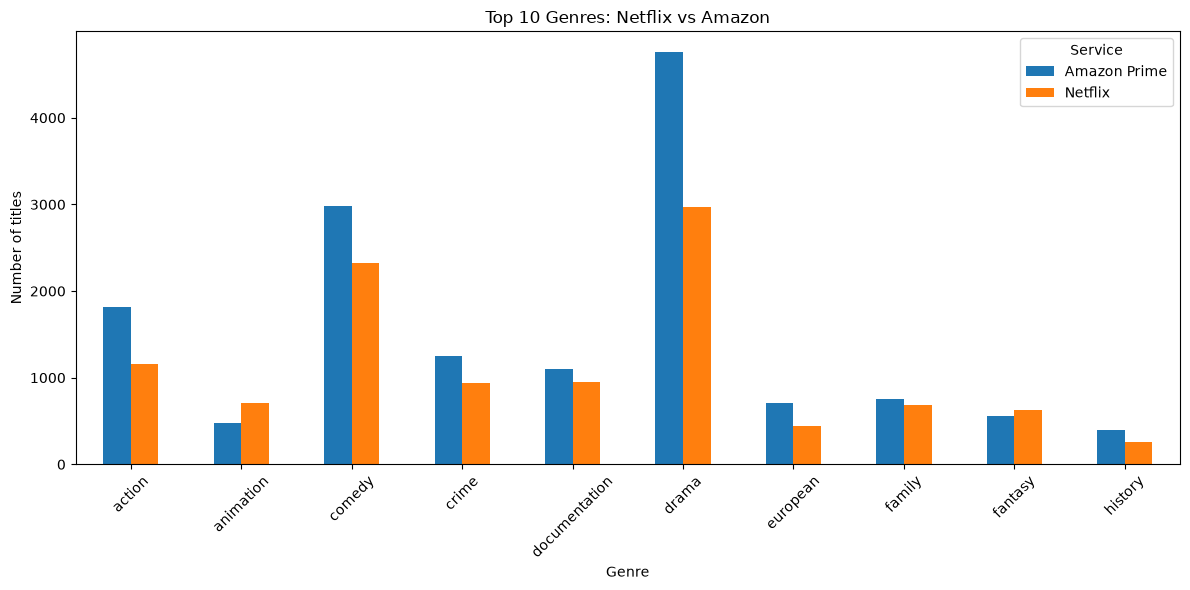

In [156]:
# number of tv shows and movies accros genres
# note: a movie or a show can have multiple genres
genre_counts = genres.groupby(["genres", "service"]).size().unstack(fill_value=0)

genre_counts.head(10).plot(kind="bar", figsize=(12, 6))

plt.xlabel("Genre")
plt.ylabel("Number of titles")
plt.title("Top 10 Genres: Netflix vs Amazon")
plt.xticks(rotation=45)
plt.legend(title="Service")
plt.tight_layout()
plt.show()

## 7.1 Which genre provide the highest-quality content?

In [157]:
# based om imdb_score
genre_ratings = (
    genres.groupby(["genres", "service"])["imdb_score"]
    .mean()
    .unstack()
)

genre_ratings


service,Amazon Prime,Netflix
genres,,
action,5.671824,6.420920
animation,6.507143,6.702063
comedy,5.994900,6.394319
crime,6.001817,6.650385
documentation,6.994837,7.009197
drama,6.132687,6.624620
european,6.308023,6.529673
family,6.147652,6.332362
fantasy,5.937009,6.558158


## 7.2 drama movies versus drama series across Netflix and Amazon Prime

In [158]:
# Count drama movies and series
drama = genres[
    genres["genres"].str.lower() == "drama"
].copy()

drama_counts = pd.crosstab(
    drama["service"],
    drama["type"]
)

print(drama_counts)


type          MOVIE  SHOW
service                  
Amazon Prime   4222   538
Netflix        1876  1092


In [159]:
# Check sample sizes for IMDb ratings
drama_summary = (
    drama.groupby(["service", "type"])
    .agg(
        total_titles=("title", "nunique"),
        rated_titles=("imdb_score", "count"),
        mean_rating=("imdb_score", "mean"),
        median_rating=("imdb_score", "median"),
        std_rating=("imdb_score", "std")
    )
    .round(2)
)

print(drama_summary)


                    total_titles  rated_titles  mean_rating  median_rating  \
service      type                                                            
Amazon Prime MOVIE          4189          4003         5.99            6.0   
             SHOW            537           482         7.29            7.4   
Netflix      MOVIE          1865          1805         6.31            6.4   
             SHOW           1087          1022         7.19            7.3   

                    std_rating  
service      type               
Amazon Prime MOVIE        1.14  
             SHOW         1.00  
Netflix      MOVIE        1.08  
             SHOW         0.96  


note: The original IMDb ratings show that drama series receive higher ratings than drama movies on both platforms. The difference is larger on Amazon Prime, where series average 7.29 compared with 5.99 for movies, than on Netflix, where the averages are 7.19 and 6.31. Netflix has higher-rated drama movies on average, while Amazon Prime series score slightly higher. Keep in mind there is more IMDb votes for Netflix then Amazon Prime

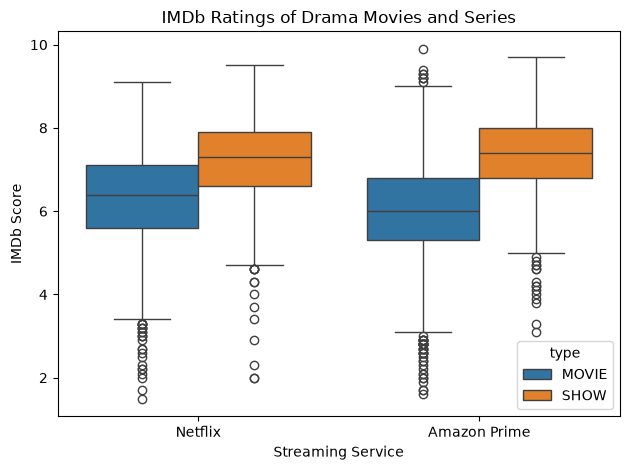

In [160]:
# Compare IMDb ratings
sns.boxplot(
    data=drama.dropna(subset=["imdb_score"]),
    x="service",
    y="imdb_score",
    hue="type"
)

plt.title("IMDb Ratings of Drama Movies and Series")
plt.xlabel("Streaming Service")
plt.ylabel("IMDb Score")
plt.tight_layout()
plt.show()

In [161]:
# Compare original and weighted IMDb ratings
rating_comparison = (
    drama.groupby(["service", "type"])
    .agg(
        rated_titles=("imdb_score", "count"),
        mean_imdb=("imdb_score", "mean"),
        median_imdb=("imdb_score", "median"),
    )
    .round(2)
)

print(rating_comparison)


                    rated_titles  mean_imdb  median_imdb
service      type                                       
Amazon Prime MOVIE          4003       5.99          6.0
             SHOW            482       7.29          7.4
Netflix      MOVIE          1805       6.31          6.4
             SHOW           1022       7.19          7.3


## 8.0: Country of origin 

In [162]:
# Are streaming services increasingly relying on particular types of content?
# Are streaming services relying on content from small number of countries, or 
# are the catelogs becoming more diverse?


## 8.1 Each country's share of the catalogue


In [163]:
# Keep titles with known production countries
country_data = catalog.dropna(
    subset=["service", "production_countries"]
).copy()

# Separate co-productions into individual country assignments
country_data["production_countries"] = (
    country_data["production_countries"].str.split(",")
)

country_data = country_data.explode("production_countries")
country_data["production_countries"] = (
    country_data["production_countries"].str.strip()
)

# Count titles associated with each country
country_counts = (
    country_data.groupby(["service", "production_countries"])
    .size()
    .reset_index(name="titles")
)

# Calculate country share within each service
country_counts["percentage"] = (
    country_counts["titles"]
    / country_counts.groupby("service")["titles"].transform("sum")
    * 100
)

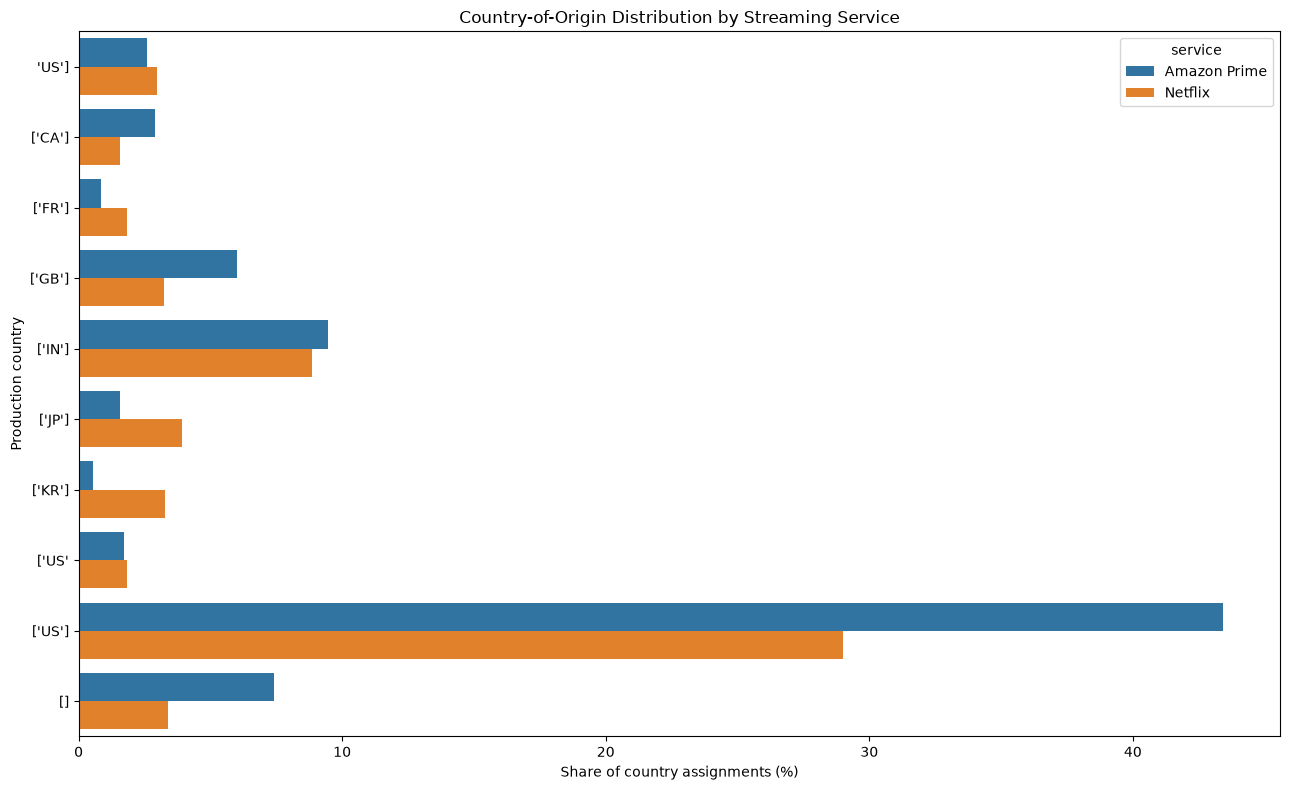

In [164]:
# Find the 10 most common countries across both services
top_countries = (
    country_counts.groupby("production_countries")["titles"]
    .sum()
    .nlargest(10)
    .index
)

plot_data = country_counts[
    country_counts["production_countries"].isin(top_countries)
]

plt.figure(figsize=(13, 8))

sns.barplot(
    data=plot_data,
    x="percentage",
    y="production_countries",
    hue="service"
)

plt.title("Country-of-Origin Distribution by Streaming Service")
plt.xlabel("Share of country assignments (%)")
plt.ylabel("Production country")
plt.tight_layout()
plt.show()